# 05 · Load-shape fingerprint (Prompt 10)

Where in the day does the weather-adjusted growth sit? A data center draws roughly the same power at 3 am as at 3 pm, so data-center
load should raise the **overnight floor** as much (in MW) as the afternoon. Growth from air-conditioning, offices or daytime industry
shows up mostly in the afternoon or at peaks. Built by `python -m glg.models.load_shape` from the Prompt 9 counterfactual.

- **night** = 1–5 am local, **afternoon** = 2–7 pm local, **peak hours** = each period's 100 hours with the highest *predicted* load.
- Residual growth since 2022 is split into a **flat 24/7** part (residual overnight at 65 °F), a **weather-sensitive** part (grows with
  CDH/HDH) and a **daytime-shape** part (the rest). The three add up to the total.
- Night hours have no solar, so night growth is untouched by rooftop solar, which lowers the daytime residual in some regions.

In [1]:
import numpy as np, polars as pl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from datetime import date
from glg.config import FIGURES_DIR
from glg.models import load_shape as ls
pl.Config(tbl_rows=40, tbl_cols=16, tbl_width_chars=230)
dec = pl.read_csv(ls.DECOMP_PATH)
metrics = pl.read_csv(ls.METRICS_PATH)
monthly = pl.read_parquet(ls.MONTHLY_PATH)
pairs = pl.read_csv(ls.PAIRS_PATH)

## Growth decomposition since 2022: 24/7 vs variable (MW, 95% intervals)

In [2]:
dec.filter(pl.col('headline')).select('ba', 'growth_pct', 'd_total_mw', 'd_flat_mw', 'd_flat_mw_lo', 'd_flat_mw_hi', 'd_weather_mw', 'd_shape_mw',
    'flat_share', 'flat_share_gbm', 'd_night_mw', 'd_afternoon_mw', 'd_peak_mw', 'night_to_afternoon', 'night_to_afternoon_lo',
    'night_to_afternoon_hi', 'verdict').with_columns(pl.col(pl.Float64).round(2))

ba,growth_pct,d_total_mw,d_flat_mw,d_flat_mw_lo,d_flat_mw_hi,d_weather_mw,d_shape_mw,…,flat_share_gbm,d_night_mw,d_afternoon_mw,d_peak_mw,night_to_afternoon,night_to_afternoon_lo,night_to_afternoon_hi,verdict
str,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,str
"""DOM""",23.63,3208.25,3305.46,2988.51,3590.05,54.59,-151.81,…,1.0,3236.11,3227.01,3165.25,1.0,0.97,1.04,"""24/7 floor"""
"""ERCO""",19.45,9440.35,8488.84,8025.54,9061.46,1308.83,-357.31,…,0.94,9126.99,10111.04,11567.21,0.9,0.87,0.94,"""24/7 floor"""
"""AZPS""",16.58,608.34,886.67,745.62,1043.23,-77.4,-200.93,…,1.37,765.77,479.21,492.16,1.6,1.33,2.08,"""24/7 floor"""
"""AZPS+SRP""",13.69,1012.78,1324.47,1166.3,1546.06,28.82,-340.52,…,1.25,1231.97,902.79,1327.11,1.36,1.22,1.62,"""24/7 floor"""
"""BPAT""",13.19,835.4,968.16,846.9,1079.33,-107.18,-25.58,…,1.18,842.63,889.29,707.54,0.95,0.88,1.02,"""24/7 floor"""
"""SWPP""",10.93,3537.75,3166.17,2893.61,3592.17,395.08,-23.5,…,0.96,3400.84,3816.59,4820.47,0.89,0.84,0.96,"""24/7 floor"""
"""GCPD""",10.57,68.27,60.29,41.22,79.32,-2.08,10.06,…,0.89,62.37,75.31,52.42,0.83,0.74,0.93,"""24/7 floor"""
"""SRP""",9.45,363.79,189.74,22.24,358.74,138.44,35.62,…,0.56,305.48,431.12,645.92,0.71,0.56,0.85,"""mixed"""
"""NEVP""",8.8,403.74,362.27,276.25,442.41,52.68,-11.2,…,0.9,363.67,334.99,520.06,1.09,0.96,1.4,"""24/7 floor"""


## Comparison pairings

In [3]:
pairs.with_columns(pl.col(pl.Float64).round(2))

dc_region,comparison,reason,dc_growth_pct,comp_growth_pct,dc_night_growth_pct,comp_night_growth_pct,pooled_growth_pct,pooled_night_growth_pct,dc_flat_share,comp_flat_share,dc_verdict,comp_verdict
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,str,str
"""DOM""","""CPLE""","""Neighbouring Carolinas utility…",23.63,2.09,27.29,3.04,3.31,4.47,1.03,0.3,"""24/7 floor""","""24/7 floor"""
"""ERCO""","""FPC""","""Hot, humid, cooling-dominated,…",19.45,2.94,22.39,4.59,3.31,4.47,0.9,0.77,"""24/7 floor""","""24/7 floor"""
"""AZPS+SRP""","""CISO""","""Hot-summer Southwest neighbour…",13.69,5.34,20.67,1.18,3.31,4.47,1.31,0.49,"""24/7 floor""","""daytime/peak"""
"""NEVP""","""CISO""","""Desert/hot-summer West neighbo…",8.8,5.34,9.48,1.18,3.31,4.47,0.9,0.49,"""24/7 floor""","""daytime/peak"""
"""BPAT""","""PACE""","""Interior West, winter-heating …",13.19,7.24,15.38,7.0,3.31,4.47,1.16,0.79,"""24/7 floor""","""mixed"""
"""GCPD""","""PACE""","""Interior West, cold-winter cli…",10.57,7.24,10.23,7.0,3.31,4.47,0.88,0.79,"""24/7 floor""","""mixed"""
"""PJM""","""MISO""","""Neighbouring multi-state ISO, …",6.4,4.11,7.92,4.74,3.31,4.47,1.1,1.09,"""24/7 floor""","""24/7 floor"""


## The *wrong if* check, second half: is the growth in the 24/7 floor or only at daytime/peak hours?

In [4]:
comparisons = ['MISO', 'NYIS', 'ISNE', 'FPC', 'CPLE', 'CISO', 'PACE', 'FPL']
focus_dc = ['DOM', 'ERCO', 'AZPS+SRP', 'NEVP', 'GCPD', 'BPAT']
for name, grp in [('data-center-heavy', focus_dc), ('comparison', comparisons)]:
    x = dec.filter(pl.col('ba').is_in(grp))
    print(f"{name:18s} median night growth {x['night_growth_pct'].median():5.1f}%   afternoon {x['afternoon_growth_pct'].median():5.1f}%   "
          f"peak hours {x['peak_growth_pct'].median():5.1f}%   verdicts {dict(x['verdict'].value_counts().iter_rows())}")

data-center-heavy  median night growth  18.0%   afternoon  12.3%   peak hours   8.6%   verdicts {'24/7 floor': 6}
comparison         median night growth   4.5%   afternoon   2.8%   peak hours   3.1%   verdicts {'no growth': 2, 'daytime/peak': 1, 'mixed': 1, '24/7 floor': 4}


## Weather-adjusted floor over time (night load ÷ mean load, both weather-adjusted)

In [5]:
metrics.filter(pl.col('ba').is_in(['DOM', 'CPLE', 'ERCO', 'FPC', 'AZPS+SRP', 'CISO', 'BPAT', 'PACE'])).pivot(
    'year', index='ba', values='night_adj_ratio').with_columns(pl.col(pl.Float64).round(3))

ba,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""BPAT""",0.854,0.858,0.859,0.86,0.86,0.86,0.871,0.87,0.874,0.88,0.889
"""CISO""",0.834,0.826,0.837,0.847,0.861,0.868,0.887,0.906,0.896,0.883,0.852
"""CPLE""",0.82,0.815,0.821,0.823,0.819,0.822,0.828,0.834,0.827,0.835,0.837
"""DOM""",null,null,0.844,0.846,0.858,0.862,0.869,0.881,0.879,0.887,0.901
"""ERCO""",0.81,0.816,0.826,0.831,0.836,0.838,0.848,0.856,0.864,0.868,0.871
"""FPC""",0.713,0.715,0.716,0.72,0.728,0.733,0.734,0.741,0.745,0.746,0.748
"""PACE""",0.868,0.873,0.875,0.877,0.874,0.882,0.874,0.88,0.879,0.873,0.87
"""AZPS+SRP""",0.805,0.808,0.809,0.814,0.816,0.82,0.821,0.829,0.836,0.883,0.872


## Chart 2: the rising floor

Trailing 12-month weather-adjusted demand index (2019 = 100) for night hours vs afternoon hours. When the same MW are added at every
hour, the night index rises faster than the afternoon one, because the night base is smaller.

2026-11-08 17:50:02,461 INFO chart2_rising_floor (light): chart2_rising_floor.png, chart2_rising_floor.svg


2026-11-08 17:50:02,965 INFO chart2_rising_floor (dark): chart2_rising_floor_dark.png, chart2_rising_floor_dark.svg


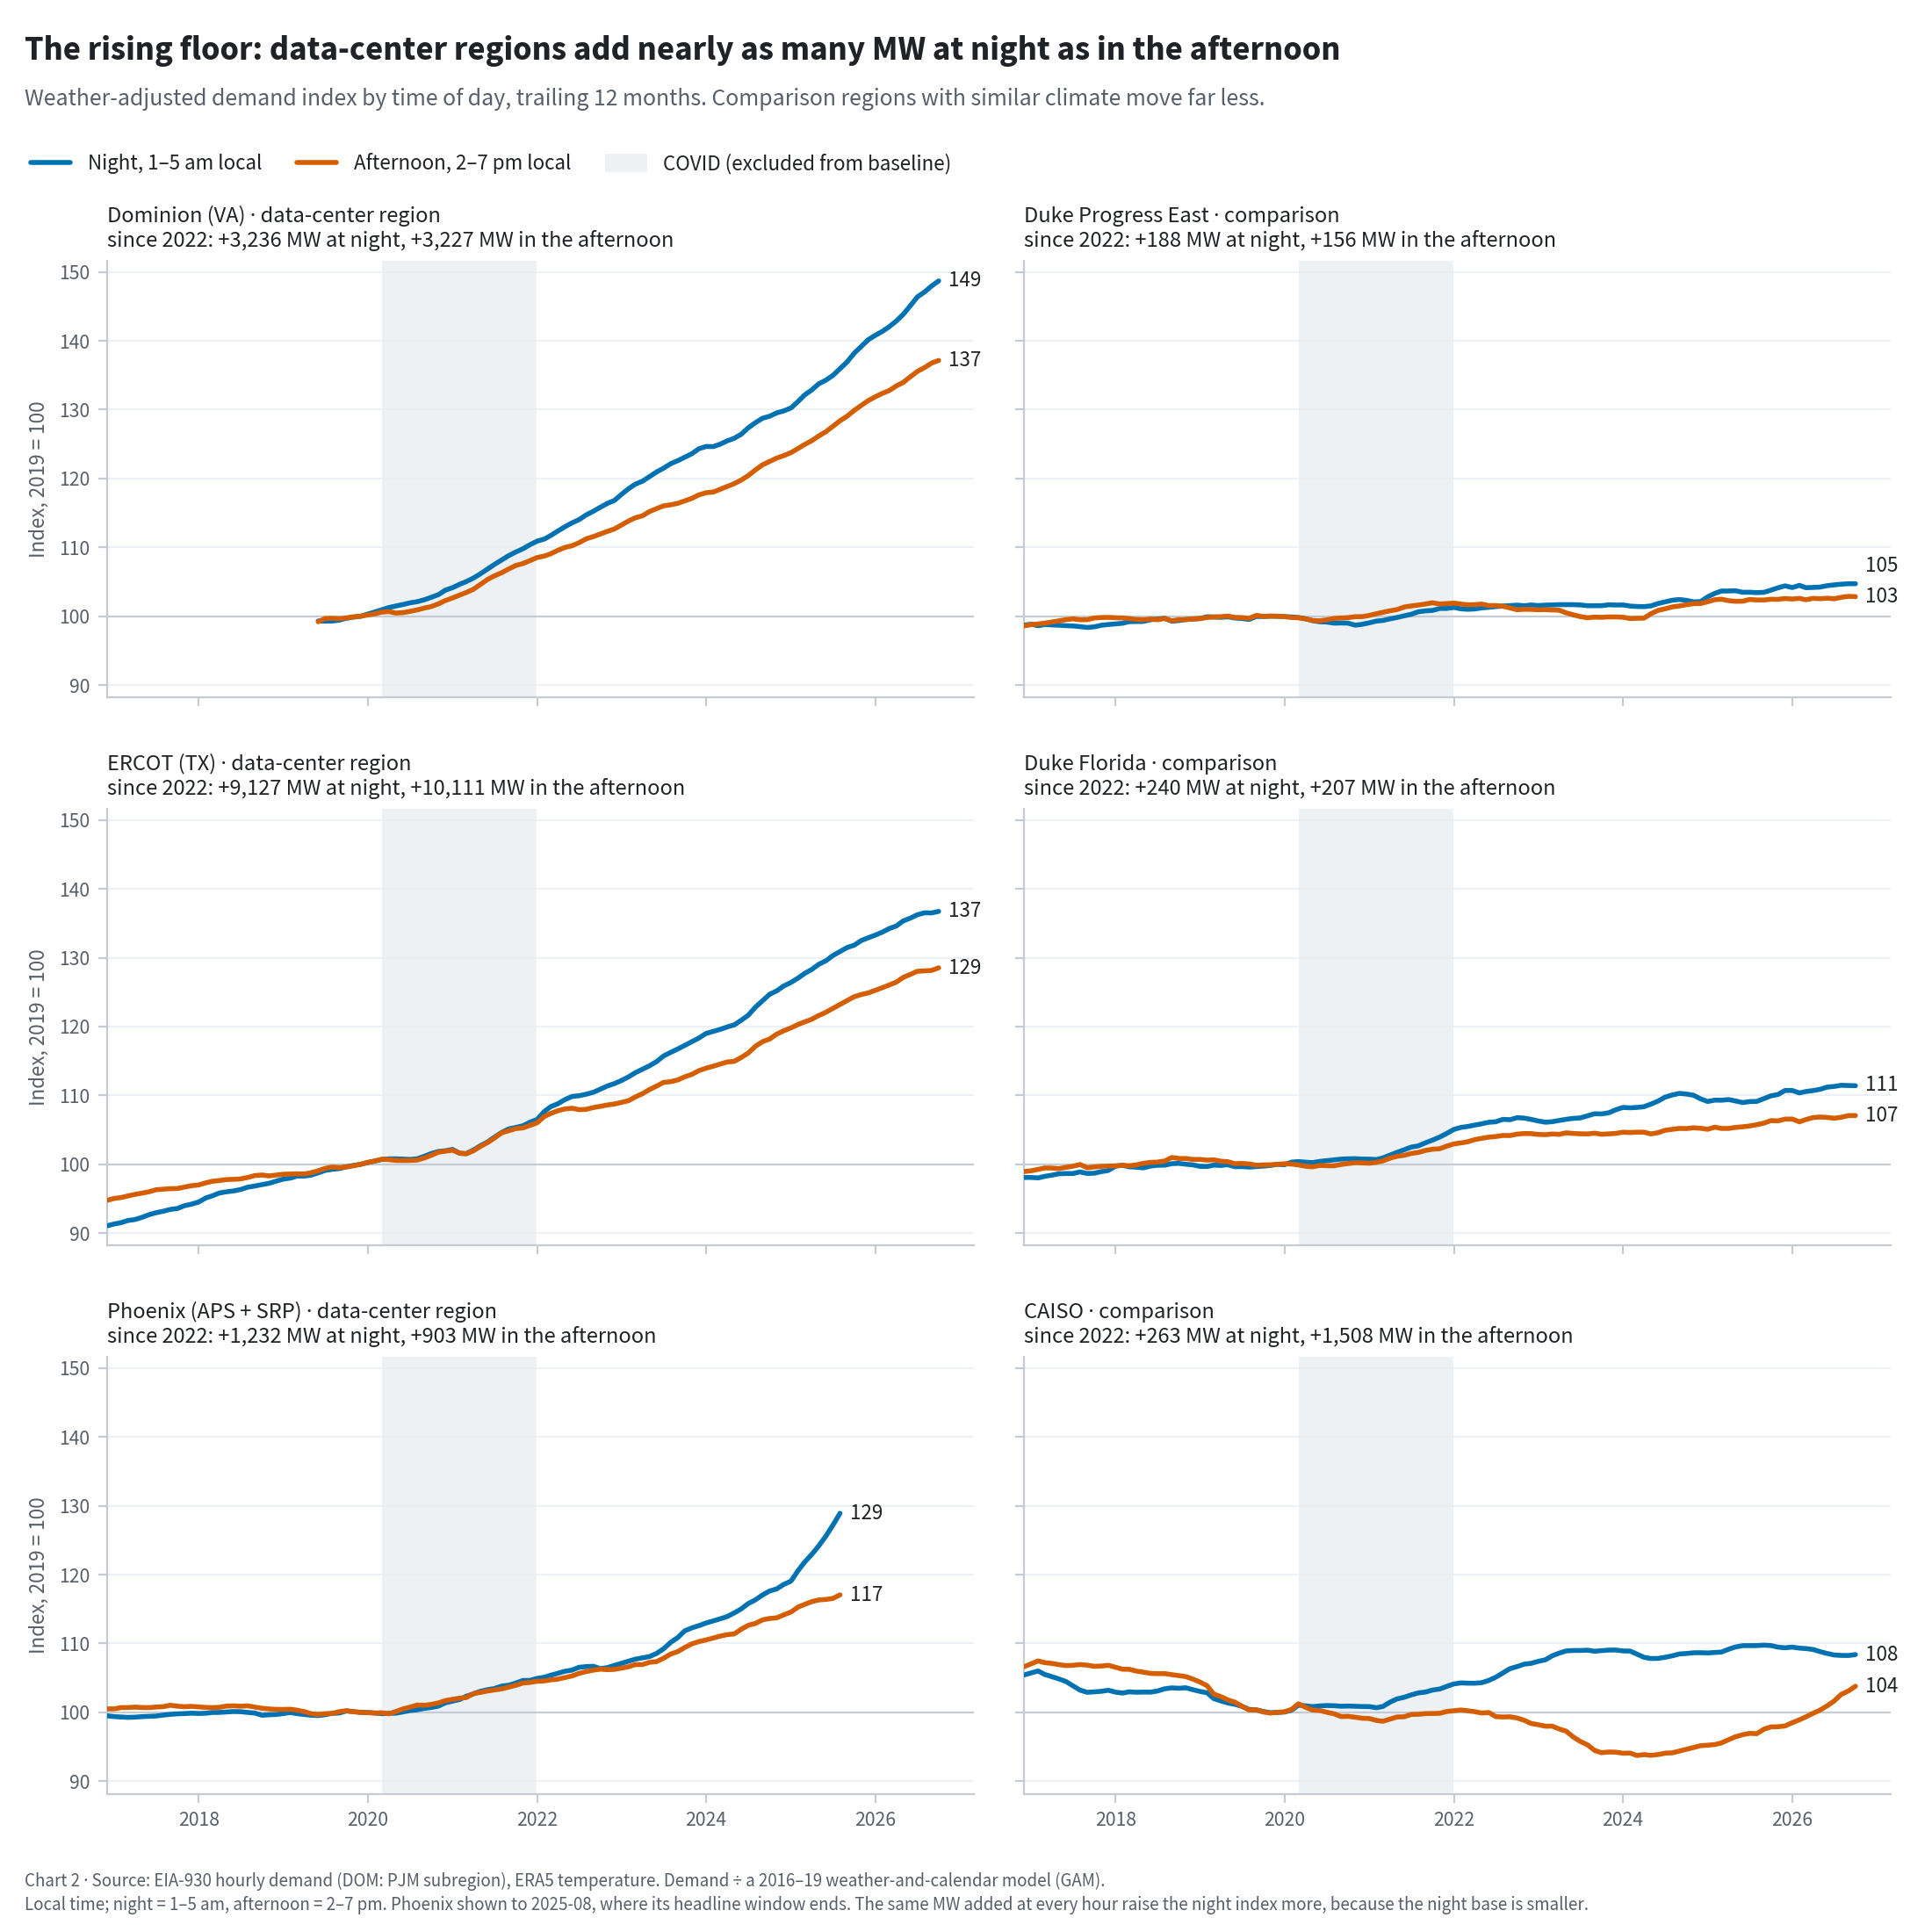

In [6]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['chart2_rising_floor'])
Image(filename=str(F.FIGURES_DIR / 'chart2_rising_floor.png'), width=900)

## Chart 3: Dominion's residual heat calendar

Each cell is one week × one local hour: actual minus modelled demand, in MW. Orange = above what the baseline relationship
predicts. A data-center floor shows as orange spreading across *all* hours at once, not as a daytime band. CPLE on the same scale.

2026-11-08 17:50:03,357 INFO chart3_dom_heat_calendar (light): chart3_dom_heat_calendar.png, chart3_dom_heat_calendar.svg


2026-11-08 17:50:03,743 INFO chart3_dom_heat_calendar (dark): chart3_dom_heat_calendar_dark.png, chart3_dom_heat_calendar_dark.svg


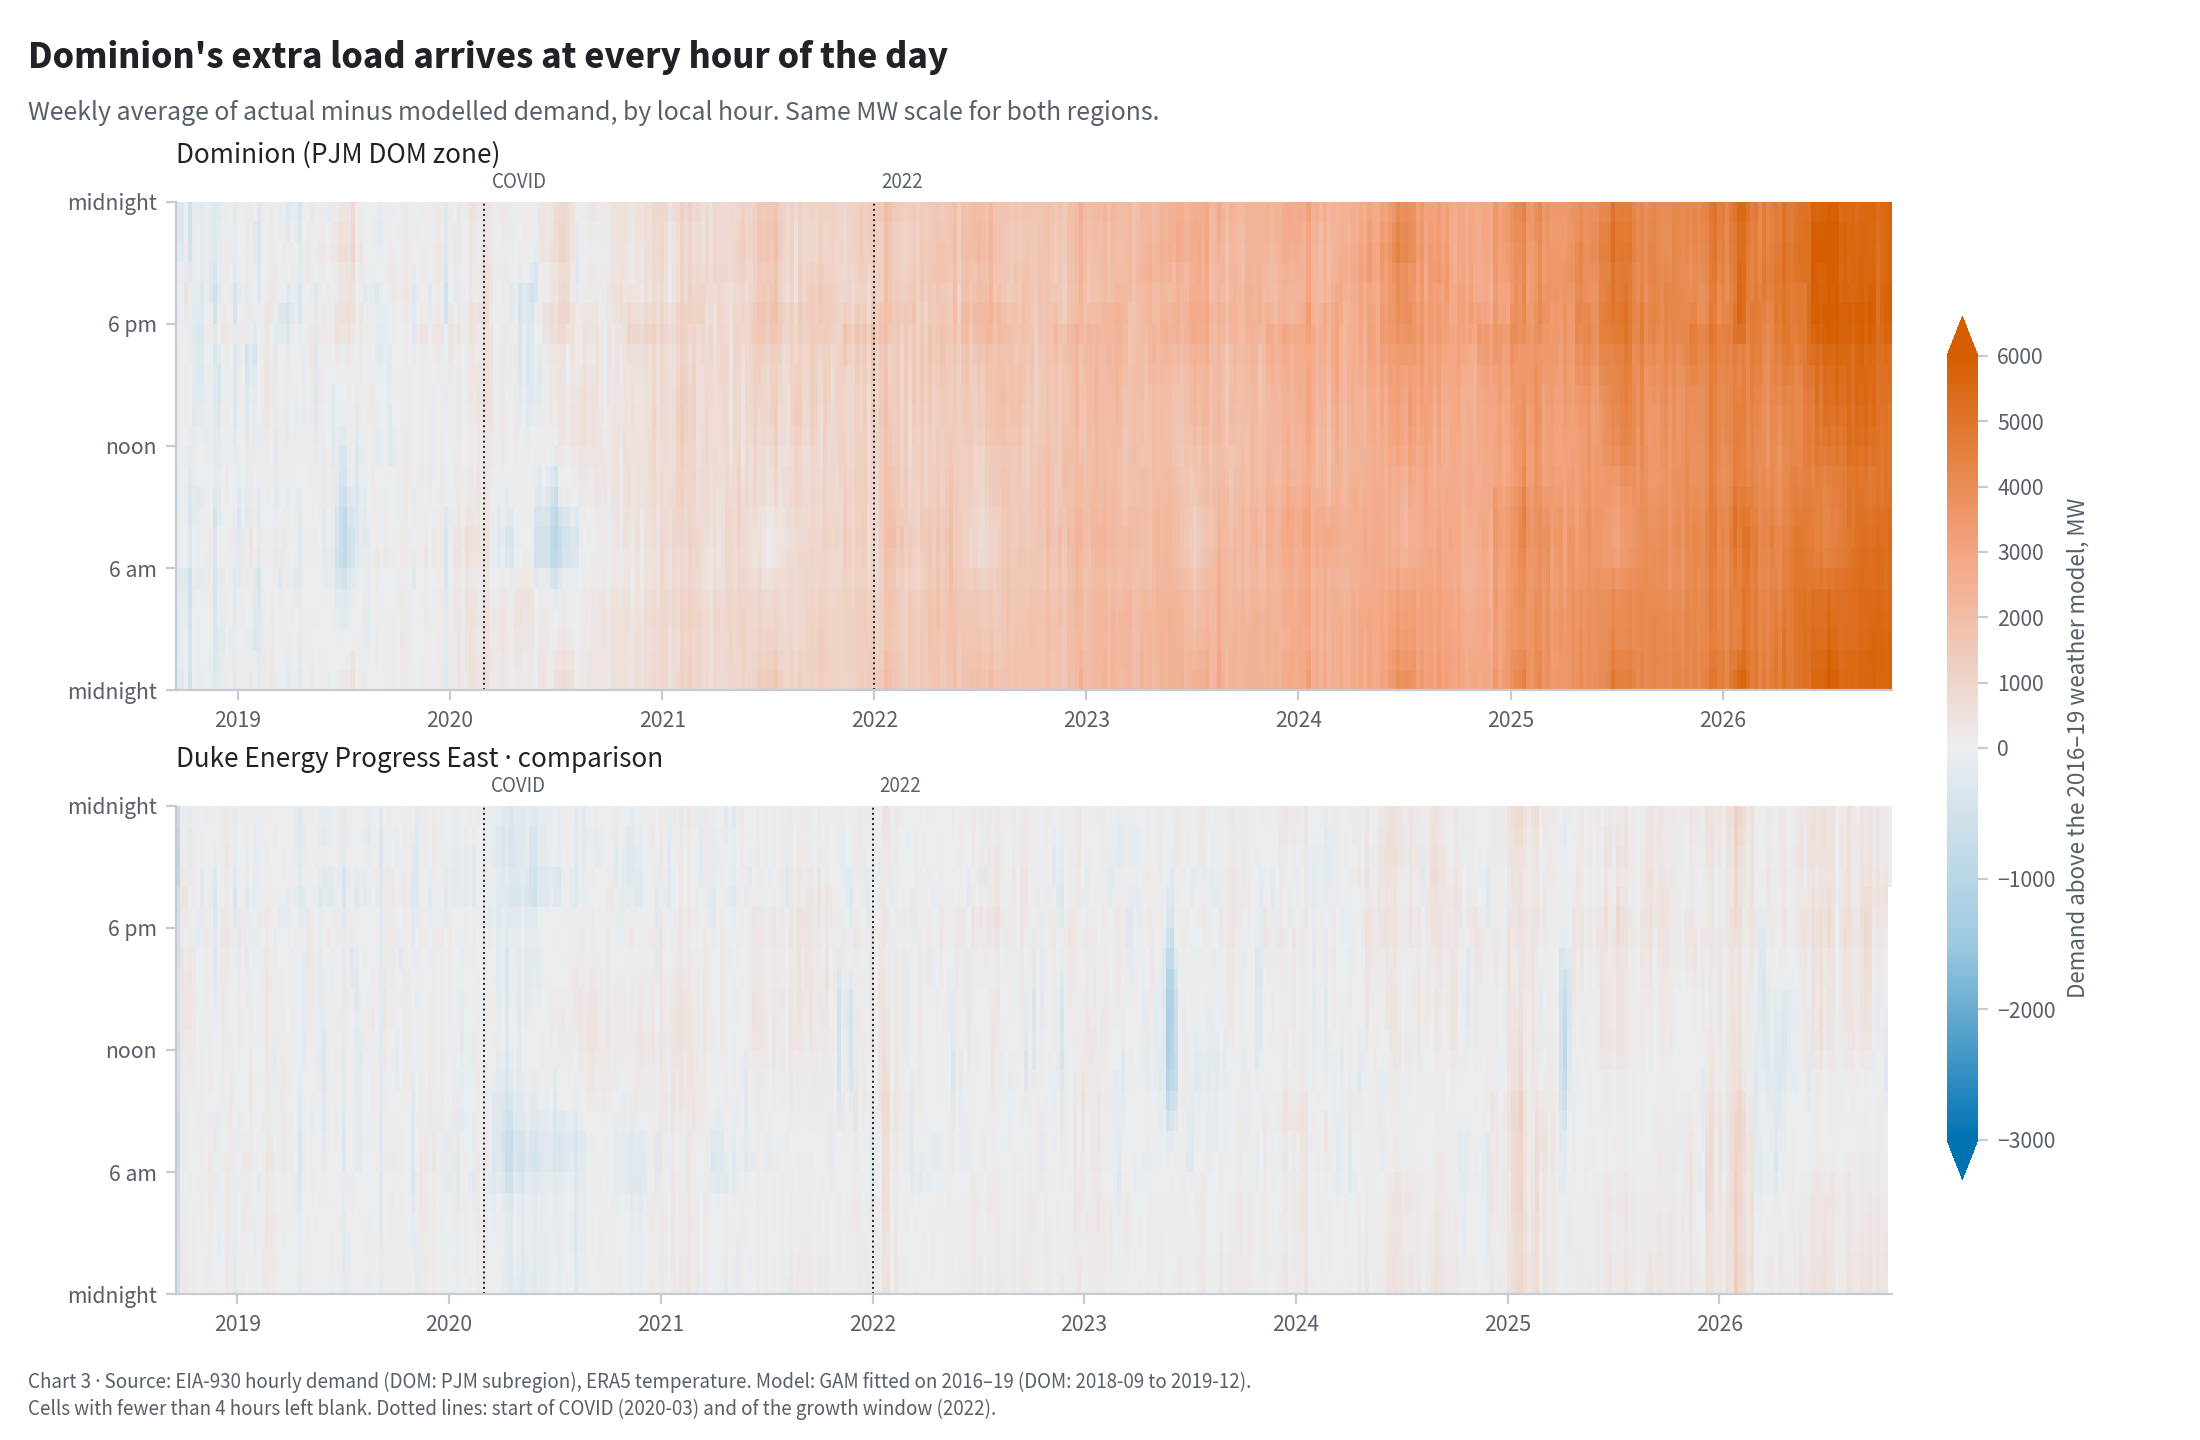

In [7]:
# Final themed figure (Prompt 16): light + dark, PNG + SVG in report/figures/
from IPython.display import Image
from glg.viz import figures as F
F.main(['chart3_dom_heat_calendar'])
Image(filename=str(F.FIGURES_DIR / 'chart3_dom_heat_calendar.png'), width=900)